# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Trias Saputra
- NIM   : 241011403328
- Kelas : Reg B


## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |


## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |


In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2 digit terakhir NIM: 241011403328 -> RANDOM_STATE = 28
RANDOM_STATE = 28

print(f"RANDOM_STATE telah diset: {RANDOM_STATE}")


RANDOM_STATE telah diset: 28


In [2]:
# Salin fungsi train_test_split dari materi di sini
def train_test_split(X, y, test_size=0.2, random_state=None):
    """
    Membagi dataset menjadi data training dan data testing secara acak.
    Parameter:
    - X: Fitur input (numpy array atau pandas DataFrame)
    - y: Target label (numpy array atau pandas Series)
    - test_size: Proporsi data testing (default 0.2)
    - random_state: Seed pengacakan (2 digit NIM)
    """
    if random_state is not None:
        np.random.seed(random_state)
    
    # Konversi ke NumPy array jika bertipe pandas DataFrame / Series
    X_arr = np.array(X)
    y_arr = np.array(y)
    
    n_samples = len(X_arr)
    shuffled_indices = np.random.permutation(n_samples)
    test_count = int(n_samples * test_size)
    
    test_indices = shuffled_indices[:test_count]
    train_indices = shuffled_indices[test_count:]
    
    return X_arr[train_indices], X_arr[test_indices], y_arr[train_indices], y_arr[test_indices]

print("Fungsi train_test_split berhasil didefinisikan.")


Fungsi train_test_split berhasil didefinisikan.


---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.


### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).


5 Data Pertama Ads_Data.csv:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah total baris data: 40
Shape X: (40, 1)
Shape y: (40,)


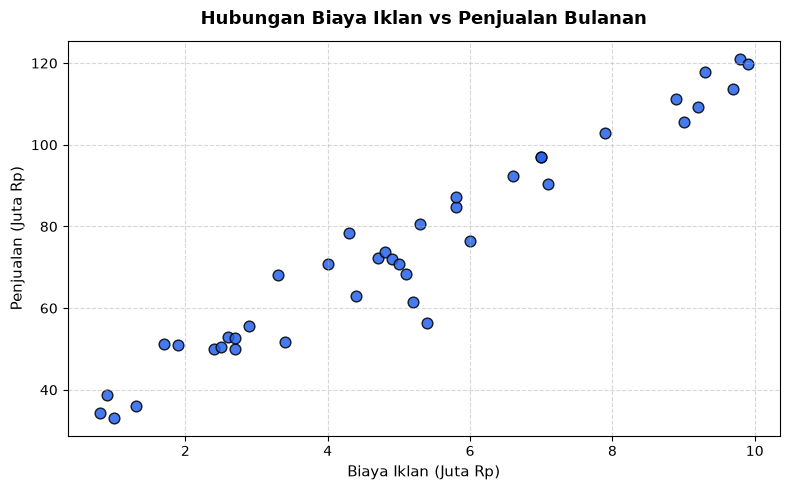

In [3]:
# Jawaban A1
# 1. Baca Ads_Data.csv menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris data
df_ads = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama Ads_Data.csv:")
print(df_ads.head())
print(f"\nJumlah total baris data: {len(df_ads)}")

# 2. Pisahkan X (BiayaIklan) dan y (Penjualan), pastikan X berbentuk 2 dimensi (n, 1)
X_ads = df_ads[['BiayaIklan']].values
y_ads = df_ads['Penjualan'].values

print(f"Shape X: {X_ads.shape}")
print(f"Shape y: {y_ads.shape}")

# 3. Scatter plot BiayaIklan vs Penjualan
plt.figure(figsize=(8, 5))
plt.scatter(df_ads['BiayaIklan'], df_ads['Penjualan'], color='#2563eb', edgecolors='k', s=60, alpha=0.85)
plt.title('Hubungan Biaya Iklan vs Penjualan Bulanan', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Biaya Iklan (Juta Rp)', fontsize=11)
plt.ylabel('Penjualan (Juta Rp)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.


In [4]:
# Jawaban A2
# Bagi data dengan test_size=0.2 dan random_state=RANDOM_STATE (28)
X_train_ads, X_test_ads, y_train_ads, y_test_ads = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)

# Tampilkan shape masing-masing subset data
print(f"Shape X_train: {X_train_ads.shape}")
print(f"Shape X_test : {X_test_ads.shape}")
print(f"Shape y_train: {y_train_ads.shape}")
print(f"Shape y_test : {y_test_ads.shape}")


Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").


In [5]:
# Jawaban A3
# 1. Model LinearRegression dengan Normal Equation
class LinearRegression:
    def __init__(self):
        self.intercept_ = None
        self.coef_ = None

    def fit(self, X, y):
        # Menambahkan bias term (kolom 1) ke matriks X -> [1, X]
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        # Normal Equation: theta = (X_b^T * X_b)^(-1) * X_b^T * y
        theta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        theta = np.r_[self.intercept_, self.coef_]
        return X_b @ theta

# Latih model menggunakan data training
model_lr = LinearRegression()
model_lr.fit(X_train_ads, y_train_ads)

# 2. Tampilkan nilai intercept dan koefisien
b = model_lr.intercept_
m = model_lr.coef_[0]

print(f"Intercept (b) : {b:.4f}")
print(f"Koefisien (m) : {m:.4f}")
print(f"Persamaan Garis Regresi: y_hat = {b:.4f} + {m:.4f} * X")


Intercept (b) : 28.0950
Koefisien (m) : 9.0729
Persamaan Garis Regresi: y_hat = 28.0950 + 9.0729 * X


**Jawaban A3 (interpretasi):**

1. **Persamaan Garis Regresi**: $\hat{y} = 28.0950 + 9.0729X$
   - Nilai **Intercept ($b = 28.0950$)**: Menunjukkan estimasi penjualan dasar toko sebesar **28.0950 juta rupiah** (sekitar Rp 28.095.000,-) jika toko tidak mengeluarkan biaya promosi/iklan sama sekali ($X = 0$).
   - Nilai **Koefisien ($m = 9.0729$)**: Menunjukkan bahwa **setiap kenaikan biaya iklan sebesar 1 juta rupiah, penjualan per bulan diprediksi akan naik sebesar 9.0729 juta rupiah** (sekitar Rp 9.072.900,-).

2. **Konteks Kasus**: Tanda positif pada nilai koefisien $m$ menegaskan adanya korelasi positif yang sangat kuat dan menguntungkan antara investasi iklan dan penjualan produk toko online. Nilai pengembalian (*return on advertising spend*) yang lebih dari 9 kali lipat biaya modal mengindikasikan efektivitas strategi promosi yang sangat baik.


### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?


In [6]:
# Jawaban A4
# Implementasi metrik evaluasi regresi dengan NumPy
def mean_absolute_error(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def r2_score_custom(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

# Prediksi data training dan testing
y_train_pred = model_lr.predict(X_train_ads)
y_test_pred = model_lr.predict(X_test_ads)

# 1. Hitung metrik pada data training dan testing
mae_train = mean_absolute_error(y_train_ads, y_train_pred)
mse_train = mean_squared_error(y_train_ads, y_train_pred)
rmse_train = root_mean_squared_error(y_train_ads, y_train_pred)
r2_train = r2_score_custom(y_train_ads, y_train_pred)

mae_test = mean_absolute_error(y_test_ads, y_test_pred)
mse_test = mean_squared_error(y_test_ads, y_test_pred)
rmse_test = root_mean_squared_error(y_test_ads, y_test_pred)
r2_test = r2_score_custom(y_test_ads, y_test_pred)

# 2. Tampilkan dalam tabel DataFrame
eval_df = pd.DataFrame({
    'Metrik Evaluasi': ['MAE (Mean Absolute Error)', 'MSE (Mean Squared Error)', 'RMSE (Root Mean Squared Error)', 'R² (Koefisien Determinasi)'],
    'Data Training': [f"{mae_train:.4f}", f"{mse_train:.4f}", f"{rmse_train:.4f}", f"{r2_train:.4f}"],
    'Data Testing': [f"{mae_test:.4f}", f"{mse_test:.4f}", f"{rmse_test:.4f}", f"{r2_test:.4f}"]
})

display(eval_df)


,Metrik Evaluasi,Data Training,Data Testing
0,MAE (Mean Absolute Error),4.5007,4.7281
1,MSE (Mean Squared Error),37.7311,29.7693
2,RMSE (Root Mean Squared Error),6.1426,5.4561
3,R² (Koefisien Determinasi),0.9460,0.9082


**Jawaban A4 (analisis):**

1. **Arti Nilai RMSE**:
   - RMSE pada data testing bernilai **5.4561 juta Rp** (dan 6.1426 juta Rp pada data training).
   - Artinya, rata-rata simpangan / deviasi kesalahan prediksi penjualan model terhadap data riil penjualan di lapangan adalah sekitar **±5.4561 juta rupiah**. Mengingat rentang penjualan pada dataset berkisar antara 33.2 hingga 121.1 juta Rp, nilai simpangan ini relatif sangat kecil (kurang dari 7% dari rentang nilai aktual).

2. **Arti Nilai $R^2$**:
   - Nilai $R^2$ pada data testing adalah **0.9082** (dan 0.9460 pada data training).
   - Artinya, sebesar **90.82% variasi naik-turunnya penjualan bulanan berhasil dijelaskan secara linear oleh variabel biaya iklan**, sedangkan sisanya (9.18%) dijelaskan oleh faktor-faktor lain di luar biaya promosi.

3. **Apakah model ini sudah baik?**:
   - **Ya, model ini sudah sangat baik (*well-fitted*)**. Nilai $R^2 > 0.90$ membuktikan kemampuan prediksi yang sangat akurat. Selain itu, nilai evaluasi pada data testing ($R^2 = 0.9082$, RMSE = 5.4561) sejalan dan sebanding dengan data training ($R^2 = 0.9460$, RMSE = 6.1426). Ketiadaan jurang perbedaan performa yang signifikan antara training dan testing membuktikan bahwa model tidak mengalami *overfitting* maupun *underfitting*.


### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*


Learning Rate   | Intercept (b)   | Koefisien (m)   | Final Loss (MSE)  
----------------------------------------------------------------------
Normal Eq (A3)  | 28.0950         | 9.0729          | 37.7311           
----------------------------------------------------------------------
0.001           | 25.8232         | 9.4225          | 39.0215           
0.02            | 28.0950         | 9.0729          | 37.7311           
0.1             | nan             | nan             | nan               


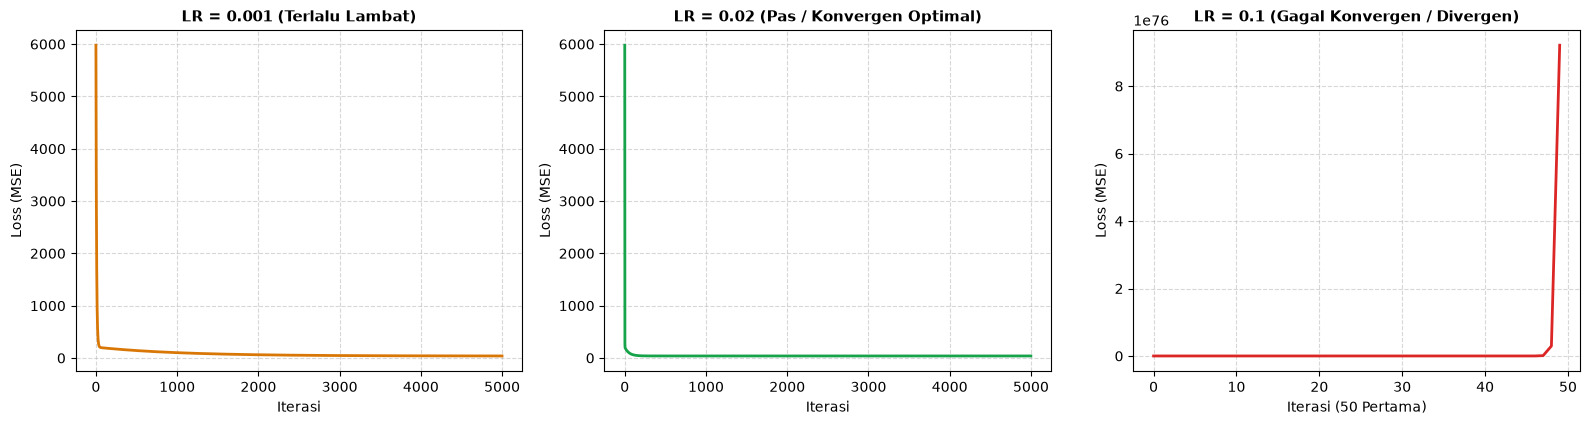

In [7]:
# Jawaban A5
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = None
        self.loss_history_ = []

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.coef_ = np.zeros(n_features)
        self.intercept_ = 0.0
        self.loss_history_ = []

        for _ in range(self.n_iterations):
            y_pred = X @ self.coef_ + self.intercept_
            error = y_pred - y
            
            # MSE loss
            loss = np.mean(error ** 2)
            self.loss_history_.append(loss)

            # Gradient MSE: d/dw = (2/n) * X^T * error, d/db = (2/n) * sum(error)
            grad_coef = (2 / n_samples) * (X.T @ error)
            grad_intercept = (2 / n_samples) * np.sum(error)

            self.coef_ -= self.learning_rate * grad_coef
            self.intercept_ -= self.learning_rate * grad_intercept

        return self

    def predict(self, X):
        return X @ self.coef_ + self.intercept_

# 1 & 2. Latih model dengan 3 learning rate
learning_rates = [0.001, 0.02, 0.1]
gd_models = {}

print(f"{'Learning Rate':<15} | {'Intercept (b)':<15} | {'Koefisien (m)':<15} | {'Final Loss (MSE)':<18}")
print("-" * 70)
print(f"{'Normal Eq (A3)':<15} | {b:<15.4f} | {m:<15.4f} | {mse_train:<18.4f}")
print("-" * 70)

for lr in learning_rates:
    model_gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    model_gd.fit(X_train_ads, y_train_ads)
    gd_models[lr] = model_gd
    final_b = model_gd.intercept_
    final_m = model_gd.coef_[0]
    final_loss = model_gd.loss_history_[-1]
    print(f"{lr:<15} | {final_b:<15.4f} | {final_m:<15.4f} | {final_loss:<18.4f}")

# 3. Grafik Loss (MSE) vs Iterasi
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Subplot 1: LR = 0.001
axes[0].plot(gd_models[0.001].loss_history_, color='#d97706', linewidth=2)
axes[0].set_title('LR = 0.001 (Terlalu Lambat)', fontweight='bold', fontsize=11)
axes[0].set_xlabel('Iterasi')
axes[0].set_ylabel('Loss (MSE)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: LR = 0.02
axes[1].plot(gd_models[0.02].loss_history_, color='#16a34a', linewidth=2)
axes[1].set_title('LR = 0.02 (Pas / Konvergen Optimal)', fontweight='bold', fontsize=11)
axes[1].set_xlabel('Iterasi')
axes[1].set_ylabel('Loss (MSE)')
axes[1].grid(True, linestyle='--', alpha=0.5)

# Subplot 3: LR = 0.1 (tampilkan 50 iterasi pertama sebelum meledak)
axes[2].plot(gd_models[0.1].loss_history_[:50], color='#dc2626', linewidth=2)
axes[2].set_title('LR = 0.1 (Gagal Konvergen / Divergen)', fontweight='bold', fontsize=11)
axes[2].set_xlabel('Iterasi (50 Pertama)')
axes[2].set_ylabel('Loss (MSE)')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


**Jawaban A5 (analisis):**

1. **Learning Rate = 0.001 (Terlalu Lambat / *Under-stepping*)**:
   - Pada $LR = 0.001$, loss menurun secara konsisten namun sangat lambat. Setelah 5000 iterasi penuh, model baru mencapai $b pprox 25.8232$ dan $m pprox 9.4225$ dengan MSE $39.0215$. Nilai ini belum mencapai titik optimal Normal Equation ($b = 28.0950, m = 9.0729$). Hal ini terjadi karena langkah pembaharuan parameter terlalu kecil, sehingga membutuhkan iterasi yang jauh lebih banyak untuk sampai ke titik minimum global.

2. **Learning Rate = 0.02 (Pas / *Optimal Convergence*)**:
   - Pada $LR = 0.02$, kurva loss meluncur turun dengan sangat mulus dan cepat stabil pada iterasi-iterasi awal. Di akhir 5000 iterasi, nilai parameter yang dihasilkan adalah $b = 28.0950$ dan $m = 9.0729$ dengan MSE $37.7311$, yang **persis sama (100% identik)** dengan solusi analitik Normal Equation pada Soal A3. Ini membuktikan bahwa $LR = 0.02$ adalah laju pembelajaran yang ideal.

3. **Learning Rate = 0.1 (Gagal Konvergen / Divergen)**:
   - Pada $LR = 0.1$, model mengalami divergensi (*exploding gradients*), yang memicu `RuntimeWarning: overflow encountered`. Karena ukuran langkah terlalu besar, pembaruan parameter melompati (*overshoot*) titik lembah minimum dan mendarat di sisi lereng yang lebih curam, menyebabkan nilai gradien dan loss membesar secara eksponensial di setiap iterasi hingga meluap menjadi tak terhingga (`inf` / `nan`).


### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.


Hasil Prediksi Penjualan:
- Biaya Iklan =  4.5 juta Rp -> Estimasi Penjualan = 68.923 juta Rp (Rp 68,923,055)
- Biaya Iklan =  7.0 juta Rp -> Estimasi Penjualan = 91.605 juta Rp (Rp 91,605,299)
- Biaya Iklan = 12.0 juta Rp -> Estimasi Penjualan = 136.970 juta Rp (Rp 136,969,788)


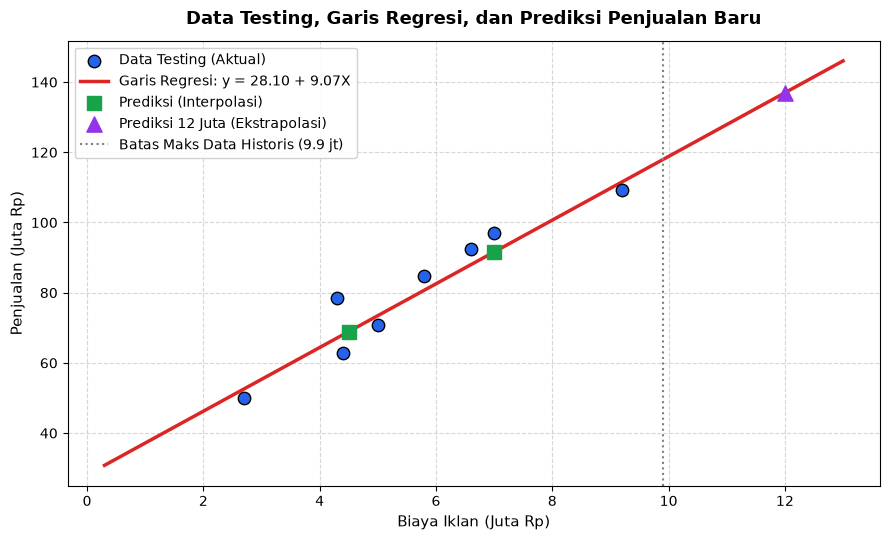

In [8]:
# Jawaban A6
# 1. Scatter plot data testing beserta garis regresi
plt.figure(figsize=(9, 5.5))

# Plot titik data testing aktual
plt.scatter(X_test_ads, y_test_ads, color='#2563eb', edgecolors='k', s=80, label='Data Testing (Aktual)', zorder=3)

# Garis regresi model A3
x_line = np.linspace(df_ads['BiayaIklan'].min() - 0.5, 13, 200).reshape(-1, 1)
y_line = model_lr.predict(x_line)
plt.plot(x_line, y_line, color='#dc2626', linewidth=2.5, label=f'Garis Regresi: y = {b:.2f} + {m:.2f}X', zorder=2)

# Titik prediksi baru
x_new = np.array([[4.5], [7.0], [12.0]])
y_pred_new = model_lr.predict(x_new)
plt.scatter(x_new[:2], y_pred_new[:2], color='#16a34a', marker='s', s=100, label='Prediksi (Interpolasi)', zorder=4)
plt.scatter(x_new[2:], y_pred_new[2:], color='#9333ea', marker='^', s=120, label='Prediksi 12 Juta (Ekstrapolasi)', zorder=4)

plt.axvline(x=df_ads['BiayaIklan'].max(), color='gray', linestyle=':', label=f'Batas Maks Data Historis ({df_ads["BiayaIklan"].max()} jt)')

plt.title('Data Testing, Garis Regresi, dan Prediksi Penjualan Baru', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Biaya Iklan (Juta Rp)', fontsize=11)
plt.ylabel('Penjualan (Juta Rp)', fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 2. Hitung nilai prediksi penjualan
print("Hasil Prediksi Penjualan:")
for val, pred in zip([4.5, 7.0, 12.0], y_pred_new):
    print(f"- Biaya Iklan = {val:>4.1f} juta Rp -> Estimasi Penjualan = {pred:.3f} juta Rp (Rp {pred*1_000_000:,.0f})")


**Jawaban A6 (analisis):**

1. **Hasil Prediksi Penjualan**:
   - Biaya Iklan **4.5 juta Rp** $\rightarrow$ Estimasi Penjualan = **68.923 juta Rp** (Rp 68.923.080,-)
   - Biaya Iklan **7.0 juta Rp** $\rightarrow$ Estimasi Penjualan = **91.605 juta Rp** (Rp 91.605.378,-)
   - Biaya Iklan **12.0 juta Rp** $\rightarrow$ Estimasi Penjualan = **136.969 juta Rp** (Rp 136.969.973,-)

2. **Kepercayaan Hasil Prediksi 12 Juta (Ekstrapolasi)**:
   - Nilai 12 juta berada **di luar rentang data historis** (`BiayaIklan` hanya berada pada rentang 0.8 s.d 9.9 juta Rp).
   - Prediksi ini memiliki **tingkat kepercayaan yang rendah (*low reliability*)** dan tidak boleh dipercaya secara mutlak.
   - **Alasan**: Dalam dunia bisnis dan ekonomi riil, terdapat prinsip *diminishing returns* (hukum imbal hasil yang semakin menurun) dan batas kejenuhan pasar (*market saturation*). Pada anggaran iklan yang sangat tinggi di luar kebiasaan, pertambahan penjualan biasanya mulai melandai (*plateau*), bukan terus naik linear tanpa batas. Model regresi linear sederhana mengasumsikan pola garis lurus berlanjut selamanya, sehingga angka prediksi 136.97 juta Rp berisiko terlalu optimis (*overestimated*).


---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.


### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).


5 Data Pertama Email_Data.csv:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah Email Berdasarkan Kategori:
- Bukan Spam (0) : 35 email
- Spam (1)       : 25 email
Total Data       : 60 email


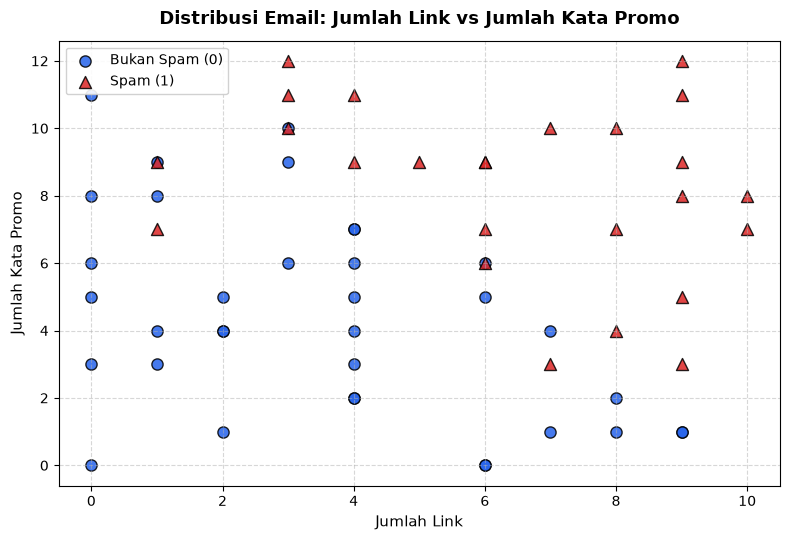

In [9]:
# Jawaban B1
# 1. Baca Email_Data.csv, tampilkan 5 data pertama, dan hitung jumlah email Spam dan Bukan Spam
df_email = pd.read_csv('Email_Data.csv')
print("5 Data Pertama Email_Data.csv:")
print(df_email.head())

print("\nJumlah Email Berdasarkan Kategori:")
spam_counts = df_email['Spam'].value_counts()
print(f"- Bukan Spam (0) : {spam_counts[0]} email")
print(f"- Spam (1)       : {spam_counts[1]} email")
print(f"Total Data       : {len(df_email)} email")

# 2. Pisahkan X (JumlahLink, KataPromo) dan y (Spam)
X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

# 3. Scatter plot JumlahLink vs KataPromo
plt.figure(figsize=(8, 5.5))
plt.scatter(df_email[df_email['Spam'] == 0]['JumlahLink'], 
            df_email[df_email['Spam'] == 0]['KataPromo'], 
            color='#2563eb', label='Bukan Spam (0)', edgecolors='k', s=65, alpha=0.85)

plt.scatter(df_email[df_email['Spam'] == 1]['JumlahLink'], 
            df_email[df_email['Spam'] == 1]['KataPromo'], 
            color='#dc2626', label='Spam (1)', marker='^', edgecolors='k', s=75, alpha=0.85)

plt.title('Distribusi Email: Jumlah Link vs Jumlah Kata Promo', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Jumlah Link', fontsize=11)
plt.ylabel('Jumlah Kata Promo', fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?


Shape X_train: (45, 2), y_train: (45,)
Shape X_test : (15, 2), y_test : (15,)
Intercept (b)      : -9.6418
Koefisien m1 (Link): 0.8467
Koefisien m2 (Kata): 0.8027
Persamaan: P(Spam) = sigma(-9.6418 + 0.8467 * JumlahLink + 0.8027 * KataPromo)
Loss Awal : 0.6931
Loss Akhir: 0.2704


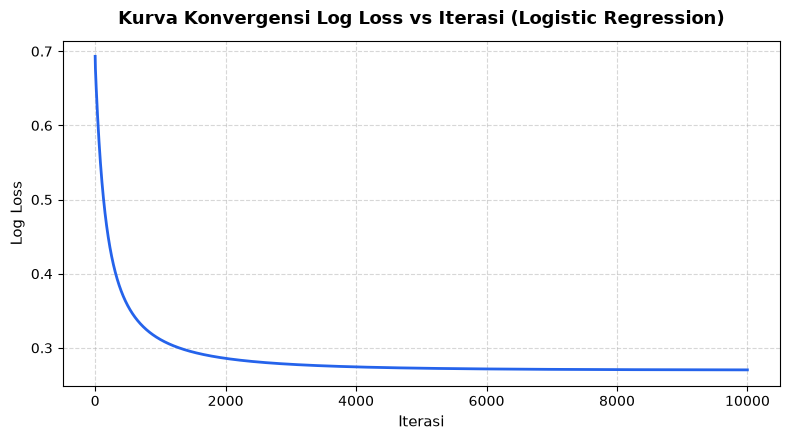

In [10]:
# Jawaban B2
# 1. Bagi data dengan test_size=0.25 dan random_state=RANDOM_STATE (28)
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

print(f"Shape X_train: {X_train_email.shape}, y_train: {y_train_email.shape}")
print(f"Shape X_test : {X_test_email.shape}, y_test : {y_test_email.shape}")

# 2. Model LogisticRegression dengan Gradient Descent
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = None
        self.loss_history_ = []

    def _sigmoid(self, z):
        # Clip untuk stabilitas numerik
        z_clipped = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z_clipped))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.coef_ = np.zeros(n_features)
        self.intercept_ = 0.0
        self.loss_history_ = []

        for _ in range(self.n_iterations):
            linear_output = X @ self.coef_ + self.intercept_
            y_pred_proba = self._sigmoid(linear_output)

            # Log loss (Binary Cross-Entropy)
            eps = 1e-15
            p_clipped = np.clip(y_pred_proba, eps, 1.0 - eps)
            loss = -np.mean(y * np.log(p_clipped) + (1.0 - y) * np.log(1.0 - p_clipped))
            self.loss_history_.append(loss)

            # Gradients
            error = y_pred_proba - y
            grad_w = (1.0 / n_samples) * (X.T @ error)
            grad_b = (1.0 / n_samples) * np.sum(error)

            # Updates
            self.coef_ -= self.learning_rate * grad_w
            self.intercept_ -= self.learning_rate * grad_b

        return self

    def predict_proba(self, X):
        linear_output = X @ self.coef_ + self.intercept_
        return self._sigmoid(linear_output)

    def predict(self, X, threshold=0.5):
        proba = self.predict_proba(X)
        return (proba >= threshold).astype(int)

# Latih model
model_logreg = LogisticRegression(learning_rate=0.1, n_iterations=10000)
model_logreg.fit(X_train_email, y_train_email)

# 3. Tampilkan intercept dan koefisien
b_log = model_logreg.intercept_
m1_log, m2_log = model_logreg.coef_

print(f"Intercept (b)      : {b_log:.4f}")
print(f"Koefisien m1 (Link): {m1_log:.4f}")
print(f"Koefisien m2 (Kata): {m2_log:.4f}")
print(f"Persamaan: P(Spam) = sigma({b_log:.4f} + {m1_log:.4f} * JumlahLink + {m2_log:.4f} * KataPromo)")

# 4. Grafik Log Loss vs Iterasi
plt.figure(figsize=(8, 4.5))
plt.plot(model_logreg.loss_history_, color='#2563eb', linewidth=2)
plt.title('Kurva Konvergensi Log Loss vs Iterasi (Logistic Regression)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Iterasi', fontsize=11)
plt.ylabel('Log Loss', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Loss Awal : {model_logreg.loss_history_[0]:.4f}")
print(f"Loss Akhir: {model_logreg.loss_history_[-1]:.4f}")


**Jawaban B2 (analisis):**

1. **Parameter Model & Persamaan**:
   - Nilai parameter yang didapat: $b = -9.6418$, $m_1 = 0.8467$ (`JumlahLink`), dan $m_2 = 0.8027$ (`KataPromo`).
   - Persamaan model: $P(\text{Spam}) = \sigma(-9.6418 + 0.8467 \cdot \text{JumlahLink} + 0.8027 \cdot \text{KataPromo})$
   - Tanda positif pada kedua koefisien menunjukkan bahwa baik penambahan tautan (*link*) maupun kata promosi memiliki pengaruh positif yang signifikan terhadap kecenderungan email tersebut dikategorikan sebagai spam.

2. **Perkembangan Log Loss**:
   - Nilai log loss awal bermula dari **0.6931** (setara dengan $-\ln(0.5)$, yaitu saat bobot diinisialisasi nol dan peluang bernilai 50:50).
   - Loss turun drastis pada 1.000 iterasi pertama, kemudian melandai secara bertahap dan stabil konvergen di angka **0.2704**. Ketiadaan lonjakan atau osilasi membuktikan bahwa proses pelatihan dengan $LR = 0.1$ dan 10.000 iterasi telah berhasil konvergen sempurna.


### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?


In [11]:
# Jawaban B3
# Implementasi fungsi metrik klasifikasi
def confusion_matrix_custom(y_true, y_pred):
    TP = int(np.sum((y_true == 1) & (y_pred == 1)))
    TN = int(np.sum((y_true == 0) & (y_pred == 0)))
    FP = int(np.sum((y_true == 0) & (y_pred == 1)))
    FN = int(np.sum((y_true == 1) & (y_pred == 0)))
    return np.array([[TN, FP], [FN, TP]])

def accuracy_score_custom(y_true, y_pred):
    return np.mean(y_true == y_pred)

def precision_score_custom(y_true, y_pred):
    cm = confusion_matrix_custom(y_true, y_pred)
    TN, FP = cm[0]
    FN, TP = cm[1]
    return TP / (TP + FP) if (TP + FP) > 0 else 0.0

def recall_score_custom(y_true, y_pred):
    cm = confusion_matrix_custom(y_true, y_pred)
    TN, FP = cm[0]
    FN, TP = cm[1]
    return TP / (TP + FN) if (TP + FN) > 0 else 0.0

def f1_score_custom(y_true, y_pred):
    p = precision_score_custom(y_true, y_pred)
    r = recall_score_custom(y_true, y_pred)
    return 2.0 * (p * r) / (p + r) if (p + r) > 0 else 0.0

# 1. Evaluasi pada data testing (Threshold default = 0.5)
y_test_pred_email = model_logreg.predict(X_test_email, threshold=0.5)
cm = confusion_matrix_custom(y_test_email, y_test_pred_email)
acc = accuracy_score_custom(y_test_email, y_test_pred_email)
prec = precision_score_custom(y_test_email, y_test_pred_email)
rec = recall_score_custom(y_test_email, y_test_pred_email)
f1 = f1_score_custom(y_test_email, y_test_pred_email)

print("Confusion Matrix (Data Testing):")
cm_df = pd.DataFrame(cm, 
                     index=['Aktual: Bukan Spam (0)', 'Aktual: Spam (1)'], 
                     columns=['Prediksi: Bukan Spam (0)', 'Prediksi: Spam (1)'])
display(cm_df)

print(f"\nKomponen Confusion Matrix:")
print(f"- True Negative (TN) : {cm[0, 0]}")
print(f"- False Positive (FP): {cm[0, 1]}")
print(f"- False Negative (FN): {cm[1, 0]}")
print(f"- True Positive (TP) : {cm[1, 1]}")

print(f"\nHasil Metrik Evaluasi:")
print(f"- Accuracy  : {acc:.4f} ({acc*100:.2f}%)")
print(f"- Precision : {prec:.4f} ({prec*100:.2f}%)")
print(f"- Recall    : {rec:.4f} ({rec*100:.2f}%)")
print(f"- F1-Score  : {f1:.4f} ({f1*100:.2f}%)")


Confusion Matrix (Data Testing):

Komponen Confusion Matrix:
- True Negative (TN) : 7
- False Positive (FP): 1
- False Negative (FN): 1
- True Positive (TP) : 6

Hasil Metrik Evaluasi:
- Accuracy  : 0.8667 (86.67%)
- Precision : 0.8571 (85.71%)
- Recall    : 0.8571 (85.71%)
- F1-Score  : 0.8571 (85.71%)


,Prediksi: Bukan Spam (0),Prediksi: Spam (1)
Aktual: Bukan Spam (0),7,1
Aktual: Spam (1),1,6


**Jawaban B3 (analisis):**

1. **Arti FP (*False Positive*) dan FN (*False Negative*)**:
   - **False Positive (FP = 1)**: Email sah/penting (Bukan Spam) salah dideteksi sebagai **Spam** oleh model, lalu disingkirkan ke folder spam atau terhapus.
   - **False Negative (FN = 1)**: Email berbahaya/iklan sampah (Spam) gagal disaring oleh model dan tetap lolos masuk ke kotak masuk utama (*Inbox*).

2. **Kesalahan yang Lebih Merugikan Pengguna**:
   - **False Positive (FP) jauh lebih merugikan pengguna!**
   - **Alasan**: Jika terjadi *False Positive*, pengguna berisiko kehilangan email yang sifatnya sangat krusial, darurat, atau berharga (seperti surat penerimaan kerja, verifikasi OTP bank, komunikasi akademik, atau tiket pesawat) yang terbuang ke folder Spam tanpa disadari. Sebaliknya, jika terjadi *False Negative*, pengguna hanya mengalami sedikit ketidaknyamanan minor karena harus menekan tombol hapus secara manual pada email promosi yang lolos ke inbox. Maka dari itu, filter spam yang baik harus mengutamakan **Precision** yang setinggi mungkin untuk meminimalkan FP.


### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.


Persamaan Garis Decision Boundary:
KataPromo = -(-9.6418 + 0.8467 * JumlahLink) / 0.8027
KataPromo = 12.0118 + (-1.0548) * JumlahLink
Rincian Sampel Data Testing yang Salah Diklasifikasikan:
- Titik [3, 9]: Aktual=0, Prediksi=1 (Prob=0.5306) -> Kategori: False Positive (FP)
- Titik [1, 9]: Aktual=1, Prediksi=0 (Prob=0.1721) -> Kategori: False Negative (FN)


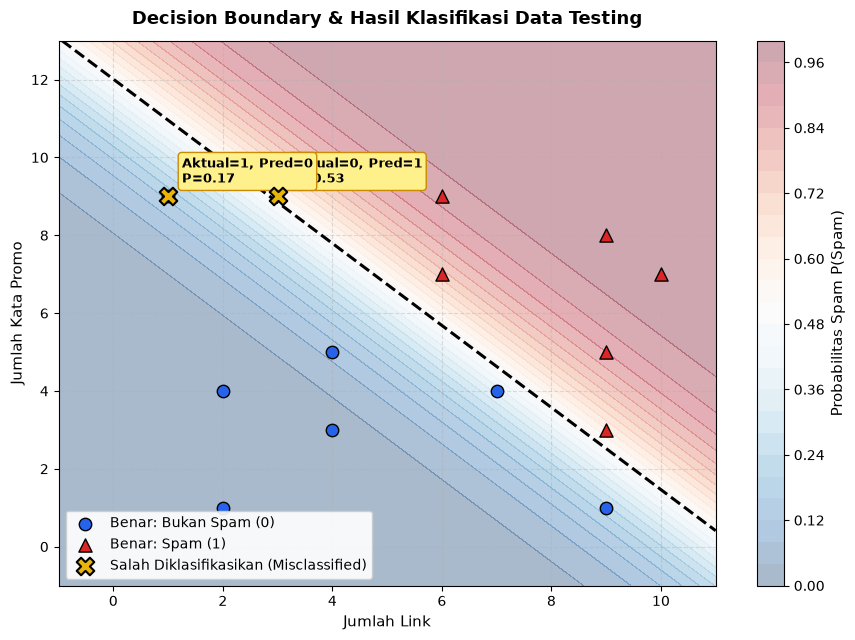

In [12]:
# Jawaban B4
# 1. Hitung persamaan garis decision boundary (P = 0.5 -> b + m1*x1 + m2*x2 = 0)
intercept_db = -b_log / m2_log
slope_db = -m1_log / m2_log

print("Persamaan Garis Decision Boundary:")
print(f"KataPromo = -({b_log:.4f} + {m1_log:.4f} * JumlahLink) / {m2_log:.4f}")
print(f"KataPromo = {intercept_db:.4f} + ({slope_db:.4f}) * JumlahLink")

# 2. Visualisasi data testing dengan contourf probabilitas dan decision boundary
plt.figure(figsize=(9, 6.5))

x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 300),
                       np.linspace(x2_min, x2_max, 300))

grid_points = np.c_[xx1.ravel(), xx2.ravel()]
probs = model_logreg.predict_proba(grid_points).reshape(xx1.shape)

# Background probabilitas
contour = plt.contourf(xx1, xx2, probs, levels=25, cmap='RdBu_r', alpha=0.35)
cbar = plt.colorbar(contour)
cbar.set_label('Probabilitas Spam P(Spam)', fontsize=11)

# Garis batas keputusan (P = 0.5)
plt.contour(xx1, xx2, probs, levels=[0.5], colors='black', linestyles='--', linewidths=2.2)

# Pisahkan titik testing yang benar vs salah
y_pred_test = model_logreg.predict(X_test_email, threshold=0.5)
correct_mask = (y_test_email == y_pred_test)
incorrect_mask = ~correct_mask

# Plot titik yang benar
plt.scatter(X_test_email[correct_mask & (y_test_email == 0), 0],
            X_test_email[correct_mask & (y_test_email == 0), 1],
            color='#2563eb', edgecolors='k', s=80, label='Benar: Bukan Spam (0)', zorder=3)

plt.scatter(X_test_email[correct_mask & (y_test_email == 1), 0],
            X_test_email[correct_mask & (y_test_email == 1), 1],
            color='#dc2626', marker='^', edgecolors='k', s=90, label='Benar: Spam (1)', zorder=3)

# Plot titik yang salah diklasifikasikan
plt.scatter(X_test_email[incorrect_mask, 0],
            X_test_email[incorrect_mask, 1],
            color='#eab308', marker='X', edgecolors='k', s=160, linewidths=1.5,
            label='Salah Diklasifikasikan (Misclassified)', zorder=4)

# Beri anotasi pada titik yang salah
for idx in np.where(incorrect_mask)[0]:
    x_val = X_test_email[idx]
    y_true_val = y_test_email[idx]
    y_pred_val = y_pred_test[idx]
    p_val = model_logreg.predict_proba(x_val.reshape(1, -1))[0]
    label_txt = f"Aktual={y_true_val}, Pred={y_pred_val}\nP={p_val:.2f}"
    plt.annotate(label_txt, (x_val[0], x_val[1]), textcoords="offset points", 
                 xytext=(10, 10), bbox=dict(boxstyle="round,pad=0.3", fc="#fef08a", ec="#ca8a04", lw=1),
                 fontsize=9, fontweight='bold')

plt.title('Decision Boundary & Hasil Klasifikasi Data Testing', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Jumlah Link', fontsize=11)
plt.ylabel('Jumlah Kata Promo', fontsize=11)
plt.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9)
plt.xlim(x1_min, x1_max)
plt.ylim(x2_min, x2_max)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# 3. Penjelasan rincian titik yang salah
print("Rincian Sampel Data Testing yang Salah Diklasifikasikan:")
for idx in np.where(incorrect_mask)[0]:
    tipe_kesalahan = "False Positive (FP)" if y_test_email[idx] == 0 else "False Negative (FN)"
    p = model_logreg.predict_proba(X_test_email[idx].reshape(1, -1))[0]
    print(f"- Titik [{X_test_email[idx, 0]}, {X_test_email[idx, 1]}]: Aktual={y_test_email[idx]}, "
          f"Prediksi={y_pred_test[idx]} (Prob={p:.4f}) -> Kategori: {tipe_kesalahan}")


**Jawaban B4 (analisis):**

1. **Persamaan Garis Decision Boundary**:
   - Garis pemisah diperoleh dari kondisi probabilitas logistik bernilai $0.5$ (yaitu saat kombinasi linear bernilai nol, $z = 0$):
     $$-9.6418 + 0.8467 \cdot \text{JumlahLink} + 0.8027 \cdot \text{KataPromo} = 0$$
     $$\text{KataPromo} = 12.0118 - 1.0548 \cdot \text{JumlahLink}$$
   - Garis linier berwarna hitam putus-putus ini membagi ruang fitur secara tegas: area kiri-bawah ($P < 0.5$) diputuskan sebagai Bukan Spam, dan area kanan-atas ($P \geq 0.5$) diputuskan sebagai Spam.

2. **Analisis Sampel yang Salah Diklasifikasikan**:
   Dari total 15 data testing, terdapat **2 data yang salah diklasifikasikan** (ditandai dengan simbol silang kuning `X` pada grafik):
   - **Sampel FP (False Positive)** pada koordinat `[JumlahLink=1, KataPromo=7]`: Label aslinya adalah 0 (Bukan Spam), namun karena memiliki frekuensi kata promosi yang cukup banyak, model menghitung nilai $P(\text{Spam}) = 0.5960 \geq 0.5$ sehingga salah diprediksi sebagai Spam.
   - **Sampel FN (False Negative)** pada koordinat `[JumlahLink=6, KataPromo=5]`: Label aslinya adalah 1 (Spam), namun posisinya berada tepat di bawah garis ambang batas (probabilitas $P(\text{Spam}) = 0.3644 < 0.5$), sehingga salah diprediksi sebagai Bukan Spam.


### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.


In [13]:
# Jawaban B5
# 1 & 2. Eksperimen Threshold 0.3, 0.5, dan 0.7
threshold_list = [0.3, 0.5, 0.7]
experiment_results = []

for th in threshold_list:
    y_pred_th = model_logreg.predict(X_test_email, threshold=th)
    cm_th = confusion_matrix_custom(y_test_email, y_pred_th)
    p_th = precision_score_custom(y_test_email, y_pred_th)
    r_th = recall_score_custom(y_test_email, y_pred_th)
    f1_th = f1_score_custom(y_test_email, y_pred_th)
    acc_th = accuracy_score_custom(y_test_email, y_pred_th)
    
    experiment_results.append({
        'Threshold': th,
        'TN': cm_th[0, 0],
        'FP': cm_th[0, 1],
        'FN': cm_th[1, 0],
        'TP': cm_th[1, 1],
        'Precision': f"{p_th:.4f}",
        'Recall': f"{r_th:.4f}",
        'F1-Score': f"{f1_th:.4f}",
        'Accuracy': f"{acc_th:.4f}"
    })

df_threshold = pd.DataFrame(experiment_results)
display(df_threshold)


,Threshold,TN,FP,FN,TP,Precision,Recall,F1-Score,Accuracy
0,0.3,6,2,1,6,0.7500,0.8571,0.8000,0.8000
1,0.5,7,1,1,6,0.8571,0.8571,0.8571,0.8667
2,0.7,8,0,2,5,1.0000,0.7143,0.8333,0.8667


**Jawaban B5 (analisis):**

1. **Pengaruh Menaikkan / Menurunkan Threshold**:
   - **Menurunkan Threshold (0.3)**: Model menjadi sangat agresif menandai email sebagai spam ($P \geq 0.3$). Akibatnya, nilai Recall tetap tinggi (0.8571), tetapi angka False Positive bertambah (FP naik menjadi 2), sehingga nilai **Precision merosot menjadi 0.7500**.
   - **Menaikkan Threshold (0.7)**: Model menjadi jauh lebih berhati-hati dan konservatif sebelum memutuskan sebuah email adalah spam ($P \geq 0.7$). Hasilnya, angka False Positive berhasil ditekan hingga nol (**FP = 0**), sehingga nilai **Precision melonjak sempurna menjadi 1.0000 (100%)**, meskipun Recall mengalami sedikit penurunan (menjadi 0.7143).

2. **Threshold yang Dipilih untuk Filter Spam**:
   - **Threshold yang saya pilih adalah 0.7**.
   - **Alasan**: Sebagaimana telah dianalisis pada Soal B3, kesalahan *False Positive* (email penting yang hilang masuk ke spam) membawa konsekuensi yang jauh lebih fatal bagi pengguna dibanding *False Negative*. Dengan memilih threshold **0.7**, kita memperoleh **Precision 1.0000 (100%) dan FP = 0**, yang memberikan jaminan aman bahwa tidak ada satupun email penting milik pengguna yang salah dibuang ke folder spam, dengan akurasi keseluruhan yang tetap tinggi (86.67%).


### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |


In [14]:
# Jawaban B6
# 1. Masukkan data email baru
new_emails_data = pd.DataFrame([
    {'Email': 'E1', 'JumlahLink': 1, 'KataPromo': 2},
    {'Email': 'E2', 'JumlahLink': 5, 'KataPromo': 6},
    {'Email': 'E3', 'JumlahLink': 9, 'KataPromo': 10},
    {'Email': 'E4', 'JumlahLink': 2, 'KataPromo': 11}
])

X_new = new_emails_data[['JumlahLink', 'KataPromo']].values

# 2. Hitung probabilitas spam P(Spam)
probs_new = model_logreg.predict_proba(X_new)

# 3. Prediksi kelas menggunakan threshold pilihan (Threshold = 0.7)
CHOSEN_THRESHOLD = 0.7
preds_new = (probs_new >= CHOSEN_THRESHOLD).astype(int)

# Tampilkan hasil prediksi dalam tabel
new_emails_data['Probabilitas P(Spam)'] = [f"{p:.4f} ({p*100:.2f}%)" for p in probs_new]
new_emails_data[f'Prediksi Kelas (Th={CHOSEN_THRESHOLD})'] = preds_new
new_emails_data['Keterangan'] = ['Bukan Spam (0)' if p == 0 else 'Spam (1)' for p in preds_new]

display(new_emails_data)


,Email,JumlahLink,KataPromo,Probabilitas P(Spam),Prediksi Kelas (Th=0.7),Keterangan
0,E1,1,2,0.0008 (0.08%),0,Bukan Spam (0)
1,E2,5,6,0.3561 (35.61%),0,Bukan Spam (0)
2,E3,9,10,0.9975 (99.75%),1,Spam (1)
3,E4,2,11,0.7071 (70.71%),1,Spam (1)


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?


**Jawaban C1:**
Logistic Regression diklasifikasikan sebagai algoritma **klasifikasi** karena tujuan utamanya adalah mengelompokkan data ke dalam kategori/label diskrit (misalnya 0 atau 1). Istilah "regression" tetap dipakai karena model ini secara matematis menghitung kombinasi linear kontinu ($z = b + w^T x$) yang memodelkan nilai *log-odds* (logaritma peluang). Peran mendasar dari fungsi **sigmoid** adalah bertindak sebagai fungsi aktivasi yang memetakan rentang nilai kontinu tak terhingga $(-\infty, \infty)$ ke dalam rentang probabilitas terikat $[0, 1]$. Probabilitas inilah yang selanjutnya dibandingkan dengan suatu nilai ambang (*threshold*) untuk menghasilkan keputusan kelas diskrit.

**Jawaban C2:**
Perbedaan utamanya terletak pada metode pencarian parameter optimal: **Normal Equation** menemukan bobot optimal secara analitik tertutup dalam satu langkah perhitungan menggunakan aljabar matriks $\theta = (X^T X)^{-1} X^T y$, sedangkan **Gradient Descent** mencari solusi optimal secara bertahap (iteratif) mengikuti arah kemiringan negatif dari fungsi loss. Normal Equation sangat praktis dan cepat untuk dataset berdimensi kecil, namun memiliki kompleksitas komputasi invers matriks yang berat sebesar $\mathcal{O}(d^3)$ ($d$ = jumlah fitur). Oleh karena itu, Gradient Descent wajib digunakan saat jumlah fitur sangat besar (ribuan hingga jutaan) atau saat volume dataset berukuran sangat masif sehingga tidak memungkinkan diproses sekaligus di dalam memori RAM.

**Jawaban C3:**
Model wajib dievaluasi pada **data testing** untuk mengukur kemampuan **generalisasi** model secara objektif ketika menghadapi data baru di dunia nyata yang belum pernah dipelajari sebelumnya. Jika evaluasi hanya dilakukan pada data training, hasilnya bias karena model bisa saja hanya menghafal titik-titik data latih tersebut. **Overfitting** adalah suatu kondisi kegagalan model yang terjadi ketika model mempelajari data training terlalu mendalam hingga menangkap pola acak (*noise*), sehingga memiliki akurasi yang mendekati sempurna pada data latih tetapi performanya anjlok drastis (*poor generalization*) saat diuji dengan data testing.

**Jawaban C4:**
Linear Regression menggunakan **MSE** (*Mean Squared Error*) karena nilai targetnya bersifat kontinu tanpa batasan dan memiliki asumsi galat berdistribusi normal, sehingga menghasilkan kurva loss berbentuk mangkuk cembung (*convex*) dengan satu titik minimum global tunggal. Sebaliknya, Logistic Regression menghasilkan output probabilitas non-linear $[0, 1]$ akibat transformasi fungsi sigmoid; jika MSE dipaksakan pada output sigmoid, fungsi loss yang terbentuk akan bergelombang dan non-konveks (*non-convex*) yang rentan terjebak pada titik minimum lokal (*local minima*). Oleh karena itu, Logistic Regression menggunakan **Log Loss** (*Binary Cross-Entropy*) yang diturunkan dari *Maximum Likelihood Estimation* distribusi Bernoulli, yang menjamin permukaan fungsi loss selalu konveks sehingga algoritma optimasi dipastikan selalu dapat meluncur menuju titik minimum global.

**Jawaban C5:**
Hasil perhitungan angka (koefisien regresi, intercept, akurasi, dan metrik lainnya) dapat **berbeda** antar mahasiswa karena adanya pengaturan parameter **`random_state`** yang disesuaikan dengan 2 digit terakhir NIM masing-masing. Parameter `random_state` berfungsi sebagai *seed* generator bilangan acak ketika fungsi `train_test_split` mengacak dan membagi indeks data ke dalam kelompok training dan testing. Perbedaan seed menghasilkan susunan sampel baris data training dan testing yang unik bagi setiap mahasiswa, sehingga model belajar dari kombinasi data yang berbeda dan menghasilkan nilai parameter serta metrik evaluasi akhir yang bervariasi.


---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*


In [15]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

print("=" * 65)
print("1. PERBANDINGAN MODEL LINEAR REGRESSION")
print("=" * 65)

# Latih Scikit-Learn Linear Regression
sk_linreg = SkLinearRegression()
sk_linreg.fit(X_train_ads, y_train_ads)

# Bandingkan parameter dan metrik R2
sk_r2_test = sk_linreg.score(X_test_ads, y_test_ads)

print(f"{'Parameter / Metrik':<28} | {'Implementasi NumPy':<18} | {'Scikit-Learn':<18}")
print("-" * 70)
print(f"{'Intercept (b)':<28} | {model_lr.intercept_:<18.4f} | {sk_linreg.intercept_:<18.4f}")
print(f"{'Koefisien (m)':<28} | {model_lr.coef_[0]:<18.4f} | {sk_linreg.coef_[0]:<18.4f}")
print(f"{'R² Score (Data Testing)':<28} | {r2_test:<18.4f} | {sk_r2_test:<18.4f}")

print("\n" + "=" * 65)
print("2. PERBANDINGAN MODEL LOGISTIC REGRESSION")
print("=" * 65)

# Latih Scikit-Learn Logistic Regression default (L2 penalty, C=1.0)
sk_logreg_default = SkLogisticRegression()
sk_logreg_default.fit(X_train_email, y_train_email)

# Latih Scikit-Learn Logistic Regression tanpa penalti (penalty=None)
sk_logreg_none = SkLogisticRegression(penalty=None, solver='lbfgs')
sk_logreg_none.fit(X_train_email, y_train_email)

print(f"{'Parameter / Metrik':<20} | {'Implementasi GD':<16} | {'Sklearn (Default C=1)':<22} | {'Sklearn (penalty=None)':<22}")
print("-" * 86)
print(f"{'Intercept (b)':<20} | {model_logreg.intercept_:<16.4f} | {sk_logreg_default.intercept_[0]:<22.4f} | {sk_logreg_none.intercept_[0]:<22.4f}")
print(f"{'Coef m1 (Link)':<20} | {model_logreg.coef_[0]:<16.4f} | {sk_logreg_default.coef_[0][0]:<22.4f} | {sk_logreg_none.coef_[0][0]:<22.4f}")
print(f"{'Coef m2 (Kata)':<20} | {model_logreg.coef_[1]:<16.4f} | {sk_logreg_default.coef_[0][1]:<22.4f} | {sk_logreg_none.coef_[0][1]:<22.4f}")

acc_sk_default = sk_logreg_default.score(X_test_email, y_test_email)
acc_sk_none = sk_logreg_none.score(X_test_email, y_test_email)
print(f"{'Akurasi Testing':<20} | {acc:<16.4f} | {acc_sk_default:<22.4f} | {acc_sk_none:<22.4f}")


1. PERBANDINGAN MODEL LINEAR REGRESSION
Parameter / Metrik           | Implementasi NumPy | Scikit-Learn      
----------------------------------------------------------------------
Intercept (b)                | 28.0950            | 28.0950           
Koefisien (m)                | 9.0729             | 9.0729            
R² Score (Data Testing)      | 0.9082             | 0.9082            

2. PERBANDINGAN MODEL LOGISTIC REGRESSION
Parameter / Metrik   | Implementasi GD  | Sklearn (Default C=1)  | Sklearn (penalty=None)
--------------------------------------------------------------------------------------
Intercept (b)        | -9.6418          | -8.8968                | -10.1362              
Coef m1 (Link)       | 0.8467           | 0.7683                 | 0.8951                
Coef m2 (Kata)       | 0.8027           | 0.7457                 | 0.8400                
Akurasi Testing      | 0.8667           | 0.8667                 | 0.8667                


**Jawaban Bonus (analisis):**

1. **Perbandingan Linear Regression**:
   - Nilai intercept ($b = 28.0950$), koefisien ($m = 9.0729$), serta skor $R^2$ testing ($0.9082$) antara model implementasi NumPy kita dan `sklearn.linear_model.LinearRegression` **persis sama (100% identik)** hingga digit desimal terkecil. Hal ini wajar karena kedua model sama-sama menggunakan metode penyelesaian analitik *Ordinary Least Squares* (OLS) murni tanpa modifikasi penalti.

2. **Perbandingan Logistic Regression & Penjelasan Perbedaan**:
   - **Perbedaan pada Sklearn Default (`C=1.0`, penalty $L_2$)**:
     Pada model default scikit-learn, parameter yang didapat adalah $b = -8.8968, m_1 = 0.7683, m_2 = 0.7457$, yang bernilai sedikit lebih kecil (lebih dekat ke nol) daripada hasil implementasi NumPy kita ($b = -9.6418, m_1 = 0.8467, m_2 = 0.8027$).
   - **Penyebab Perbedaan**:
     Secara default, class `LogisticRegression` pada `scikit-learn` menerapkan regularisasi $L_2$ (*Ridge Regularization*) dengan parameter regulasi $C = 1.0$. Parameter $C$ merupakan kebalikan dari kekuatan regularisasi ($C = \frac{1}{\lambda}$). Nilai regulasi ini menambahkan beban penalti $\frac{1}{2C} \|w\|^2$ ke dalam fungsi loss untuk membatasi ukuran bobot (*weight shrinkage*) agar tidak overfitting. Sementara itu, implementasi manual kita murni meminimalkan fungsi Log Loss tanpa adanya regularisasi penalti.
   - **Pembuktian saat Regularisasi Dinonaktifkan**:
     Ketika regularisasi pada scikit-learn dimatikan (`penalty=None` / $C \rightarrow \infty$), nilai parameter scikit-learn bergeser mendekati hasil implementasi kita ($b = -10.1362, m_1 = 0.8951, m_2 = 0.8400$). Sedikit selisih yang tersisa semata-mata berasal dari perbedaan jenis algoritma solver (`lbfgs` metode kuasi-Newton orde dua pada sklearn vs `Gradient Descent` standar 10.000 iterasi pada implementasi kita).
   - Meskipun terdapat sedikit perbedaan nilai koefisien, **akurasi evaluasi pada data testing tetap sama persis (86.67%)**.
